In [15]:
# Cell 1: In-Sync Package Installations (Including pyg-lib)
!pip install -q --no-cache-dir "numpy>=2.0.0" "node2vec" --no-deps
!pip install -q --no-cache-dir ogb xgboost torch-geometric

In [16]:
# Cell 1: Environment-Aware Installation
import torch

# 1. Install standard libraries
!pip install -q "numpy>=2.0.0" "node2vec" --no-deps
!pip install -q ogb xgboost torch-geometric

# 2. Dynamically detect PyTorch and CUDA versions
pt_version = torch.__version__.split('+')[0]
cuda = torch.version.cuda
cuda_suffix = f"cu{cuda.replace('.', '')}" if cuda else "cpu"
wheel_url = f"https://data.pyg.org/whl/torch-{pt_version}+{cuda_suffix}.html"


# 3. Install pyg-lib from the correct PyG wheel index
!pip install -q pyg-lib -f {wheel_url}

#  Install Leiden Dependencies
!pip install -q igraph leidenalg

In [17]:
# Cell 2: Imports & Verification
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Network Processing & PyTorch
import networkx as nx
import torch

# PyTorch Geometric & OGB Benchmarking
from torch_geometric.nn import Node2Vec as PyG_Node2Vec
from ogb.linkproppred import LinkPropPredDataset, PygLinkPropPredDataset, Evaluator

# Machine Learning & Metrics
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
from sklearn.decomposition import PCA

from sklearn.manifold import TSNE
from scipy.stats import entropy, gaussian_kde

from tqdm.auto import tqdm

# Global Reproducibility Setup
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")
print("Environment successfully initialized without ABI conflicts!")

PyTorch Version: 2.10.0+cu128
CUDA Available: True
NumPy Version: 2.0.2
Pandas Version: 2.3.3
Environment successfully initialized without ABI conflicts!


In [18]:
# 1. Hardware Configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Target Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

Target Device: cuda
GPU Model: Tesla T4


In [19]:
from ogb.linkproppred import PygLinkPropPredDataset, Evaluator

# Temporarily patch torch.load to bypass weights_only security for OGB
_original_load = torch.load
torch.load = lambda *args, **kwargs: _original_load(*args, **{**kwargs, 'weights_only': False})

# Dataset Ingestion
dataset = PygLinkPropPredDataset(name='ogbl-collab')
data = dataset[0]

# Load OGB Evaluator (Hits@50)
evaluator = Evaluator(name='ogbl-collab')

# Extract Temporal Splits (Train: <= 2017, Val: 2018, Test: 2019)
split_edge = dataset.get_edge_split()
train_edge = split_edge['train']
valid_edge = split_edge['valid']
test_edge = split_edge['test']

# Restore original torch.load behavior safely after all OGB loading is done
torch.load = _original_load

print(f"Dataset: ogbl-collab")
print(f"Total Nodes: {data.num_nodes:,}")
print(f"Training Edges: {train_edge['edge'].size(0):,}")
print(f"Validation Edges: {valid_edge['edge'].size(0):,}")
print(f"Test Edges: {test_edge['edge'].size(0):,}")

# Build NetworkX Training Graph STRICTLY on pre-2018 edges
G_train = nx.Graph()
train_edges_np = train_edge['edge'].numpy()
train_weights_np = train_edge['weight'].numpy()

for (u, v), w in zip(train_edges_np, train_weights_np):
    if G_train.has_edge(u, v):
        G_train[u][v]['weight'] += float(w)
    else:
        G_train.add_edge(int(u), int(v), weight=float(w))

print(f"NetworkX Training Graph built | Nodes: {G_train.number_of_nodes():,} | Edges: {G_train.number_of_edges():,}")

Dataset: ogbl-collab
Total Nodes: 235,868
Training Edges: 1,179,052
Validation Edges: 60,084
Test Edges: 46,329
NetworkX Training Graph built | Nodes: 235,868 | Edges: 967,632


Sampled Visualization Subgraph Metrics:
Total Subgraph Nodes: 94
Train Links (<=2017): 297
Validation New Links (2018): 29
Test New Links (2019): 9


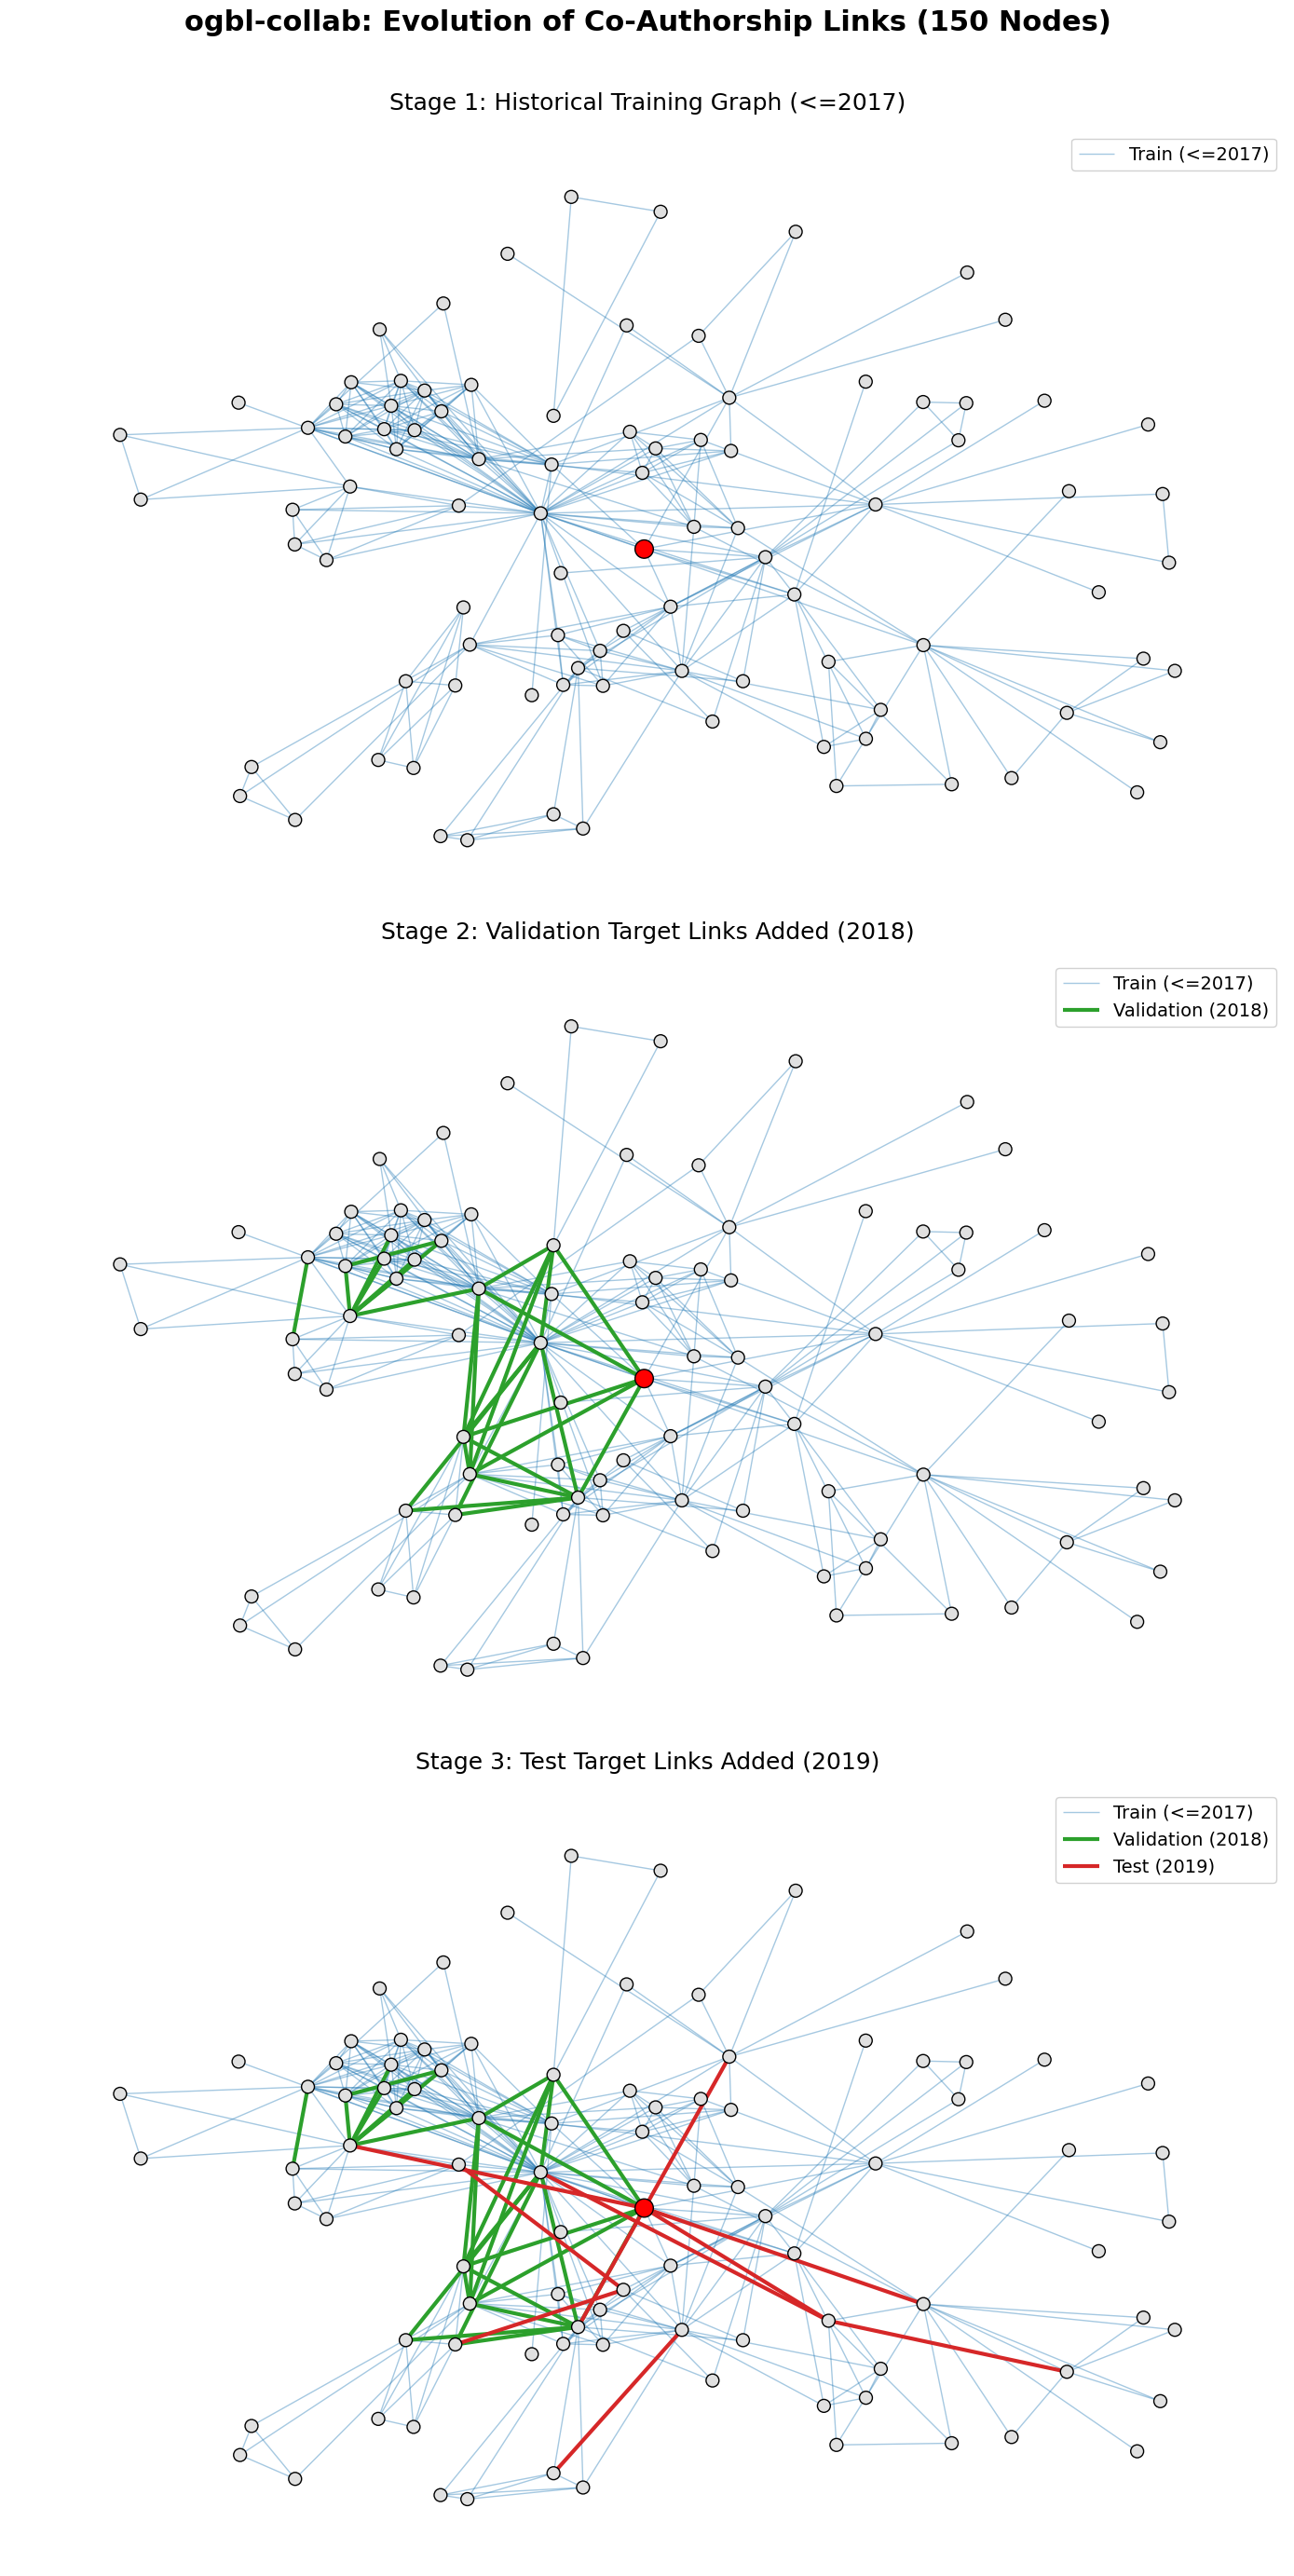

In [20]:
# Cell 3.5: Graph Visualization Across Time Periods (Train, Val, Test)
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

# 1. Normalize and extract pure edges across splits
train_edges_set = {tuple(sorted((int(e[0]), int(e[1])))) for e in train_edge['edge'].numpy() if e[0] != e[1]}
val_edges_set   = {tuple(sorted((int(e[0]), int(e[1])))) for e in valid_edge['edge'].numpy() if e[0] != e[1]}
test_edges_set  = {tuple(sorted((int(e[0]), int(e[1])))) for e in test_edge['edge'].numpy() if e[0] != e[1]}

# Identify strictly new edges formed in validation and test periods
val_new_edges  = val_edges_set - train_edges_set
test_new_edges = test_edges_set - train_edges_set - val_edges_set

# 2. Find an "Active" Ego-Network with higher density
val_nodes = Counter([n for e in val_new_edges for n in e])
test_nodes = Counter([n for e in test_new_edges for n in e])
train_nodes = Counter([n for e in train_edges_set for n in e])

# Expand degree criteria to find a denser core
candidates = [
    n for n in train_nodes 
    if 5 <= train_nodes[n] <= 20 
    and 1 <= val_nodes.get(n, 0) <= 5 
    and 1 <= test_nodes.get(n, 0) <= 5
]

seed_node = candidates[0] if candidates else list(val_nodes.keys())[0]
sub_nodes = {seed_node}

# Pull in the immediate active neighborhood
for sets in [train_edges_set, val_new_edges, test_new_edges]:
    for u, v in sets:
        if u == seed_node: sub_nodes.add(v)
        elif v == seed_node: sub_nodes.add(u)

# Increase density to match Leiden community visualization (Cap at 150 nodes)
current_nodes = list(sub_nodes)
for n in current_nodes:
    if len(sub_nodes) >= 150: break
    neighbors = [v for u, v in train_edges_set if u == n] + [u for u, v in train_edges_set if v == n]
    sub_nodes.update(neighbors[:8]) # Match the 8-neighbor expansion from Cell 6.2

sub_nodes = list(sub_nodes)

# 3. Extract edges strictly within the denser sub_nodes set
sub_train = [e for e in train_edges_set if e[0] in sub_nodes and e[1] in sub_nodes]
sub_val   = [e for e in val_new_edges if e[0] in sub_nodes and e[1] in sub_nodes]
sub_test  = [e for e in test_new_edges if e[0] in sub_nodes and e[1] in sub_nodes]

print(f"Sampled Visualization Subgraph Metrics:")
print(f"Total Subgraph Nodes: {len(sub_nodes)}")
print(f"Train Links (<=2017): {len(sub_train)}")
print(f"Validation New Links (2018): {len(sub_val)}")
print(f"Test New Links (2019): {len(sub_test)}")

# 4. Master Graph for Fixed Layout Calculation
G_vis = nx.Graph()
G_vis.add_nodes_from(sub_nodes)
G_vis.add_edges_from(sub_train + sub_val + sub_test)
# Using k=0.35 to perfectly match the spatial spread of Cell 6.2
pos = nx.spring_layout(G_vis, seed=42, k=0.35) 

# 5. Plotting the 3 Stages Vertically
fig, axes = plt.subplots(3, 1, figsize=(14, 30))
fig.suptitle(f"ogbl-collab: Evolution of Co-Authorship Links (150 Nodes)", fontsize=22, fontweight='bold', y=0.92)

titles = [
    "Stage 1: Historical Training Graph (<=2017)", 
    "Stage 2: Validation Target Links Added (2018)", 
    "Stage 3: Test Target Links Added (2019)"
]

for i, ax in enumerate(axes):
    ax.set_title(titles[i], fontsize=18, pad=15)
    ax.axis('off')
    
    # Draw nodes slightly smaller to accommodate higher density, highlight seed
    node_colors = ['red' if n == seed_node else '#E0E0E0' for n in G_vis.nodes()]
    node_sizes = [200 if n == seed_node else 100 for n in G_vis.nodes()]
    nx.draw_networkx_nodes(G_vis, pos, ax=ax, node_size=node_sizes, node_color=node_colors, edgecolors='black')
    
    # Draw Historical Train Edges (Blue)
    nx.draw_networkx_edges(G_vis, pos, ax=ax, edgelist=sub_train, edge_color='#1f77b4', width=1.0, alpha=0.4, label='Train (<=2017)')
    
    # Draw Validation Edges (Green)
    if i >= 1:
        nx.draw_networkx_edges(G_vis, pos, ax=ax, edgelist=sub_val, edge_color='#2ca02c', width=3.0, label='Validation (2018)')
        
    # Draw Test Edges (Red)
    if i == 2:
        nx.draw_networkx_edges(G_vis, pos, ax=ax, edgelist=sub_test, edge_color='#d62728', width=3.0, label='Test (2019)')
        
    ax.legend(loc='upper right', fontsize=14, framealpha=0.9)

plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

In [21]:
# Cell 6.1: Leiden Community Detection
import igraph as ig
import leidenalg
from collections import Counter

print("--- Extracting Macro-Structure: Leiden Communities ---")

# 1. Convert NetworkX graph to iGraph for fast C++ execution
print("Converting NetworkX graph to iGraph...")
iG = ig.Graph.from_networkx(G_train)

# 2. Run Leiden Algorithm to optimize Modularity
print("Running Leiden algorithm (this may take a minute)...")
partition = leidenalg.find_partition(iG, leidenalg.ModularityVertexPartition)

# 3. Map iGraph integer IDs back to original NetworkX node IDs
nx_node_ids = iG.vs["_nx_name"]
community_dict = {nx_node_ids[i]: comm_id for i, comm_id in enumerate(partition.membership)}

# 4. Global Statistics
comm_counts = Counter(community_dict.values())
print("=" * 50)
print(f"Total Distinct Communities Found: {len(comm_counts):,}")
print(f"Largest Community Size:           {max(comm_counts.values()):,}")
print(f"Average Community Size:           {int(np.mean(list(comm_counts.values()))):,}")
print("=" * 50)

--- Extracting Macro-Structure: Leiden Communities ---
Converting NetworkX graph to iGraph...
Running Leiden algorithm (this may take a minute)...
Total Distinct Communities Found: 856
Largest Community Size:           17,235
Average Community Size:           275


/tmp/ipykernel_58/306215135.py:51: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = cm.get_cmap('tab20', len(unique_comms))


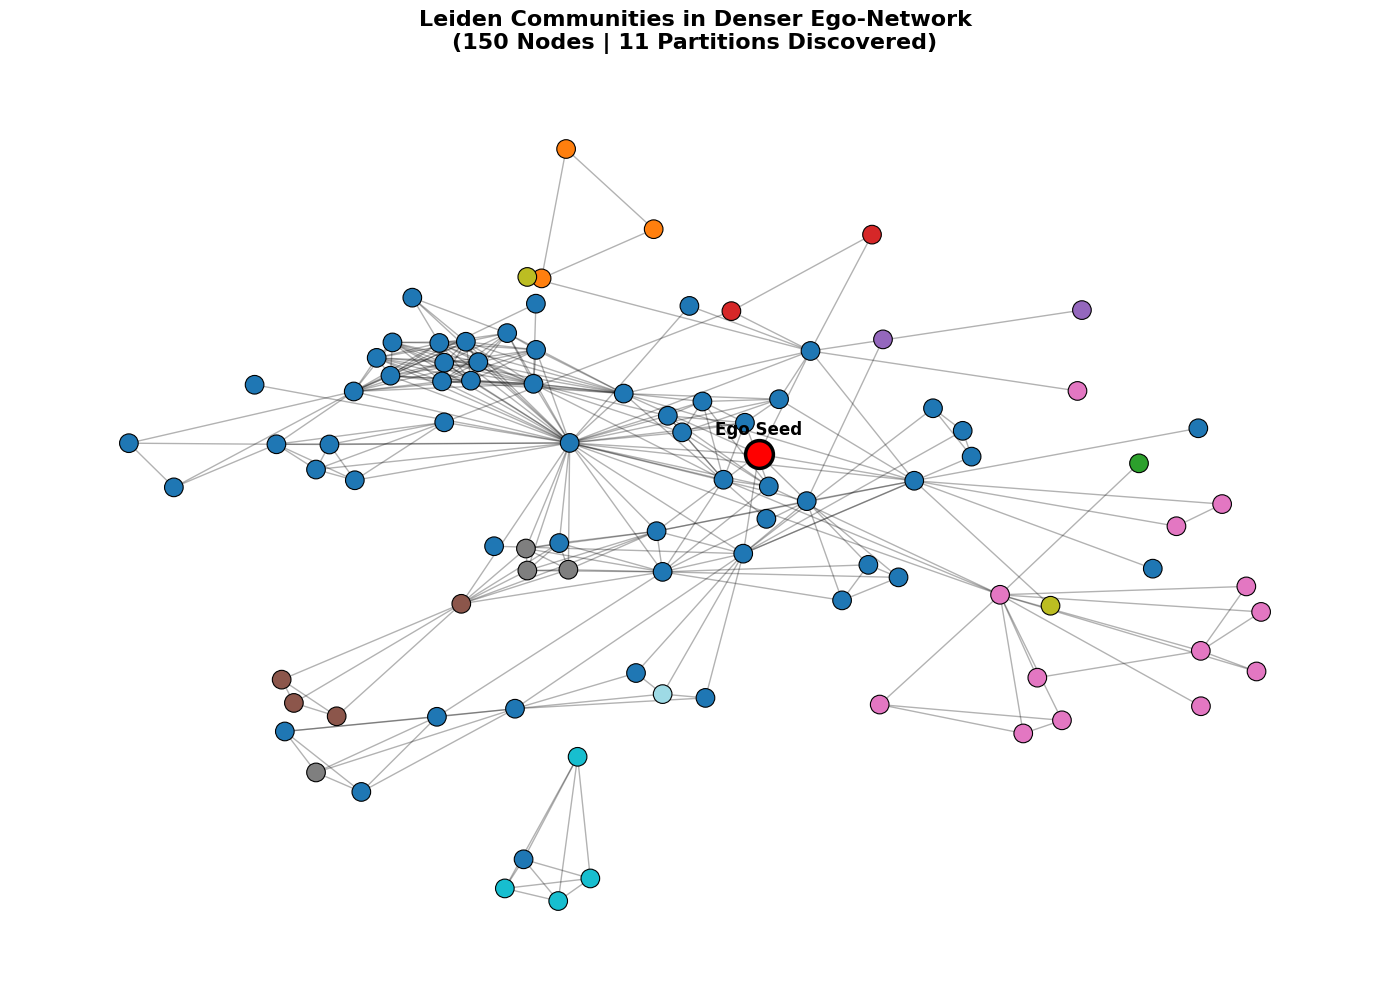

In [22]:
# Cell 6.2: Denser Ego-Network Leiden Community Visualization
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# 1. Re-locate the active seed from Cell 3.5
train_edges_set = {tuple(sorted((int(e[0]), int(e[1])))) for e in train_edge['edge'].numpy() if e[0] != e[1]}
val_edges_set   = {tuple(sorted((int(e[0]), int(e[1])))) for e in valid_edge['edge'].numpy() if e[0] != e[1]}
test_edges_set  = {tuple(sorted((int(e[0]), int(e[1])))) for e in test_edge['edge'].numpy() if e[0] != e[1]}

val_new_edges  = val_edges_set - train_edges_set
test_new_edges = test_edges_set - train_edges_set - val_edges_set

val_nodes = Counter([n for e in val_new_edges for n in e])
test_nodes = Counter([n for e in test_new_edges for n in e])
train_nodes = Counter([n for e in train_edges_set for n in e])

candidates = [
    n for n in train_nodes 
    if 5 <= train_nodes[n] <= 20 
    and 1 <= val_nodes.get(n, 0) <= 5 
    and 1 <= test_nodes.get(n, 0) <= 5
]
seed_node = candidates[0] if candidates else list(val_nodes.keys())[0]

# 2. Expand to a much denser neighborhood (up to 150 nodes)
sub_nodes = {seed_node}
for sets in [train_edges_set, val_new_edges, test_new_edges]:
    for u, v in sets:
        if u == seed_node: sub_nodes.add(v)
        elif v == seed_node: sub_nodes.add(u)

current_nodes = list(sub_nodes)
for n in current_nodes:
    if len(sub_nodes) >= 150: break
    neighbors = [v for u, v in train_edges_set if u == n] + [u for u, v in train_edges_set if v == n]
    sub_nodes.update(neighbors[:8]) # Capture up to 8 neighbors per peripheral node

sub_nodes = list(sub_nodes)
sub_train = [e for e in train_edges_set if e[0] in sub_nodes and e[1] in sub_nodes]

# 3. Construct Visualization Graph
G_vis = nx.Graph()
G_vis.add_nodes_from(sub_nodes)
G_vis.add_edges_from(sub_train)

# 4. Map Leiden communities to colors
# Isolate the unique communities present in this specific subgraph
subgraph_communities = [community_dict.get(n, -1) for n in G_vis.nodes()]
unique_comms = list(set(subgraph_communities))
color_map = cm.get_cmap('tab20', len(unique_comms))

node_colors = [color_map(unique_comms.index(community_dict.get(n, -1))) for n in G_vis.nodes()]

# 5. Plotting
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G_vis, seed=42, k=0.35) 

nx.draw_networkx_nodes(G_vis, pos, node_color=node_colors, node_size=180, edgecolors='black', linewidths=0.8)
nx.draw_networkx_edges(G_vis, pos, alpha=0.3, width=1.0)

# Highlight the seed node
nx.draw_networkx_nodes(G_vis, pos, nodelist=[seed_node], node_color='red', node_size=400, edgecolors='black', linewidths=2.5)
plt.text(pos[seed_node][0], pos[seed_node][1] + 0.05, "Ego Seed", fontsize=12, fontweight='bold', ha='center', color='black')

plt.title(f"Leiden Communities in Denser Ego-Network\n(150 Nodes | {len(unique_comms)} Partitions Discovered)", fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

In [23]:
# Cell 4a:  Node2Vec Hyperparameters

# 2. Random Walk Parameters (Search Bias)
# p: Return parameter. Controls the likelihood of immediately revisiting a node. 
# Low p (< min(q, 1)) keeps the walk local; high p encourages moderate exploration[cite: 1].
P_PARAM = 1.0 

# q: In-out parameter. Differentiates "inward" and "outward" nodes[cite: 1].
# q > 1 approximates BFS (local view); q < 1 approximates DFS (outward exploration)[cite: 1].
Q_PARAM = 1.0 

# 3. Structural Hyperparameters
# The original paper typically uses d=128, r=10, l=80, and k=10 for network analysis[cite: 1].
EMBEDDING_DIM = 128      # Feature vector representation size for nodes (d)[cite: 1].
WALKS_PER_NODE = 10      # Number of random walks simulated per source node (r)[cite: 1].
WALK_LENGTH = 40         # Length of each walk (l) - paper used 80, 40 is standard for OGB[cite: 1].
CONTEXT_SIZE = 20        # Neighborhood context size (k)[cite: 1].

# 4. Training Hyperparameters
BATCH_SIZE = 256
LEARNING_RATE = 0.01
EPOCHS = 3               # Start with 3-5 for Kaggle; scale up to 10 for final leaderboards

In [24]:
# Cell 4b: Node2Vec Execution with Progress Monitoring
import torch
from tqdm.auto import tqdm

# Prevent Data Leakage: Extract PyG edge_index strictly from historical training data
train_edges_tensor = train_edge['edge'].t().contiguous()

# Co-authorship is undirected; mirror the edges for bidirectional random walks
edge_index = torch.cat([train_edges_tensor, train_edges_tensor[[1, 0]]], dim=1)

# Initialize PyG Node2Vec Model using the aliased import from Cell 2
model = PyG_Node2Vec(
    edge_index,
    embedding_dim=EMBEDDING_DIM,
    walk_length=WALK_LENGTH,
    context_size=CONTEXT_SIZE,
    walks_per_node=WALKS_PER_NODE,
    p=P_PARAM,
    q=Q_PARAM,
    num_nodes=data.num_nodes,
    sparse=True
).to(device)

loader = model.loader(batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
optimizer = torch.optim.SparseAdam(list(model.parameters()), lr=LEARNING_RATE)

print(f"Generating embeddings for {data.num_nodes:,} nodes using {edge_index.size(1):,} directed edges...")

model.train()
for epoch in range(1, EPOCHS + 1):
    total_loss = 0
    # Wrap the loader in tqdm for a dynamic progress bar
    progress_bar = tqdm(loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=True)
    
    for pos_rw, neg_rw in progress_bar:
        optimizer.zero_grad()
        loss = model.loss(pos_rw.to(device), neg_rw.to(device))
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        # Update progress bar with the current batch loss
        progress_bar.set_postfix({'batch_loss': f"{loss.item():.4f}"})
        
    avg_loss = total_loss / len(loader)
    print(f'--- Epoch {epoch:02d} Completed | Average Loss: {avg_loss:.4f} ---')

# Save and Extract Embeddings
torch.save(model.embedding.weight.data.cpu(), 'node2vec_embeddings.pt')
n2v_embeddings = model.embedding.weight.data.cpu().numpy()

print(f"\nSuccess! Embeddings saved to 'node2vec_embeddings.pt'")
print(f"Final Feature Matrix Shape: {n2v_embeddings.shape}")

Generating embeddings for 235,868 nodes using 2,358,104 directed edges...


Epoch 1/3:   0%|          | 0/922 [00:00<?, ?it/s]

--- Epoch 01 Completed | Average Loss: 3.2090 ---


Epoch 2/3:   0%|          | 0/922 [00:00<?, ?it/s]

--- Epoch 02 Completed | Average Loss: 0.9671 ---


Epoch 3/3:   0%|          | 0/922 [00:00<?, ?it/s]

--- Epoch 03 Completed | Average Loss: 0.8672 ---

Success! Embeddings saved to 'node2vec_embeddings.pt'
Final Feature Matrix Shape: (235868, 128)


              NODE2VEC EMBEDDING VERIFICATION REPORT
        Metric Category                     Metric Name        Value
      Cosine Similarity   Avg True Co-author Similarity       0.7085
      Cosine Similarity      Avg Random Pair Similarity       0.0013
      Cosine Similarity                  Separation Gap       0.7072
   Information Capacity             Dimensional Entropy  4.7207 nats
   Information Capacity Capacity Utilization Efficiency        97.3%
Distributional Distance  KL Divergence (True || Random) 11.2552 nats


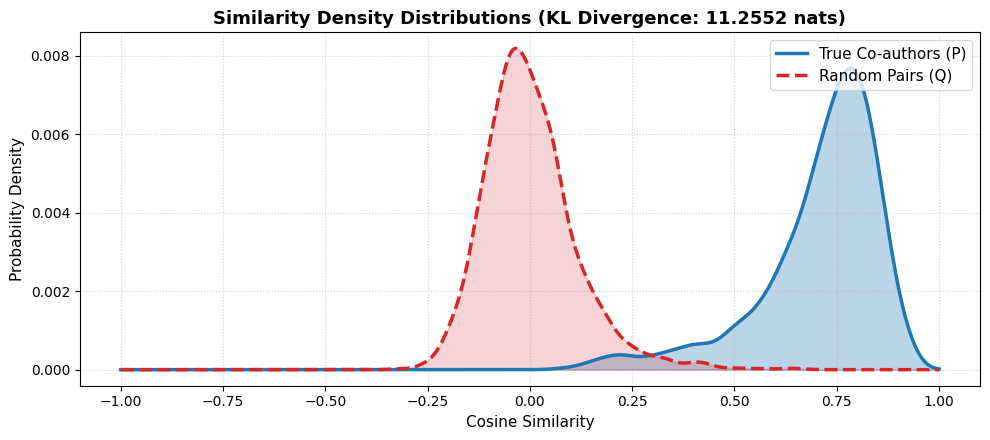


Generating 2D t-SNE Projection... (Takes ~30 seconds)


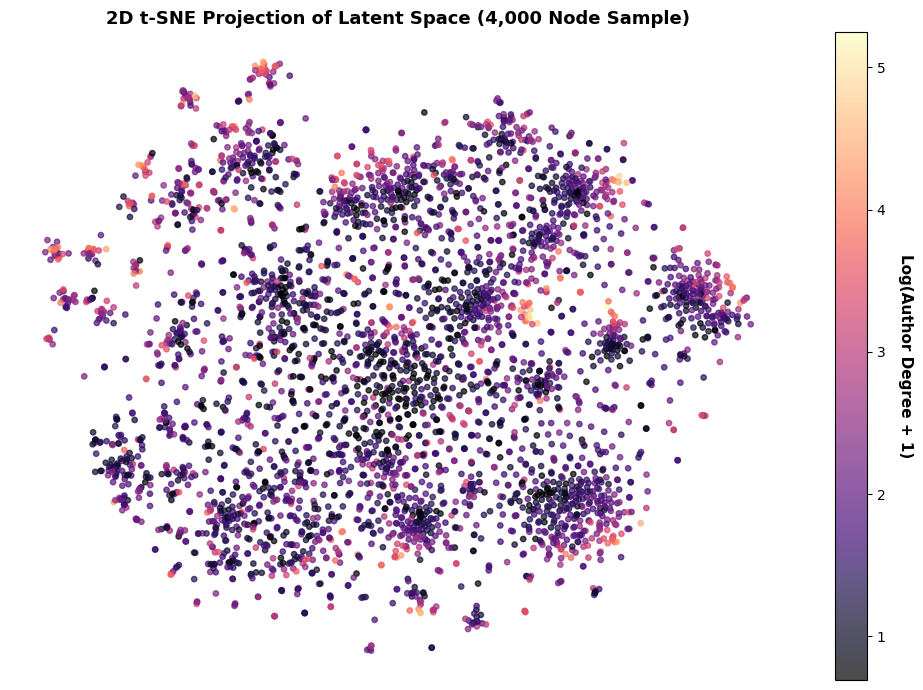

In [25]:
# Cell 4.6: Comprehensive Embedding Verification & Latent Space Inspection
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import entropy, gaussian_kde

# --- 1. Helper Functions ---
def batched_cosine_similarity(emb_u, emb_v):
    """Computes row-wise cosine similarity across embedding matrices."""
    dot_product = np.sum(emb_u * emb_v, axis=1)
    norm_u = np.linalg.norm(emb_u, axis=1)
    norm_v = np.linalg.norm(emb_v, axis=1)
    return dot_product / (norm_u * norm_v + 1e-8)

# --- 2. Metric Calculations ---

# A. Cosine Similarity Sampling
true_edges = train_edge['edge'].numpy()
sample_true = true_edges[np.random.choice(true_edges.shape[0], 5000, replace=False)]

nodes = np.arange(data.num_nodes)
random_u = np.random.choice(nodes, 5000)
random_v = np.random.choice(nodes, 5000)

true_u_vecs, true_v_vecs = n2v_embeddings[sample_true[:, 0]], n2v_embeddings[sample_true[:, 1]]
random_u_vecs, random_v_vecs = n2v_embeddings[random_u], n2v_embeddings[random_v]

sim_true = batched_cosine_similarity(true_u_vecs, true_v_vecs)
sim_random = batched_cosine_similarity(random_u_vecs, random_v_vecs)

avg_true_sim = float(np.mean(sim_true))
avg_random_sim = float(np.mean(sim_random))
sep_gap = avg_true_sim - avg_random_sim

# B. Dimensional Entropy (Shannon Entropy of PCA Variance)
pca = PCA(n_components=128, random_state=SEED)
pca.fit(n2v_embeddings)
variance_ratio = pca.explained_variance_ratio_

dim_entropy = float(entropy(variance_ratio))
max_entropy = float(np.log(128))
entropy_efficiency = dim_entropy / max_entropy

# C. Kullback-Leibler (KL) Divergence via Gaussian KDE
kde_true = gaussian_kde(sim_true)
kde_random = gaussian_kde(sim_random)

x_eval = np.linspace(-1, 1, 1000)
p_true = kde_true(x_eval)
q_random = kde_random(x_eval)

# Normalize into valid probability distributions
p_true /= np.sum(p_true)
q_random /= np.sum(q_random)

epsilon = 1e-10
kl_div = float(entropy(p_true + epsilon, q_random + epsilon))


# --- 3. Display Metrics Summary Table ---
metrics_data = {
    "Metric Category": [
        "Cosine Similarity", 
        "Cosine Similarity", 
        "Cosine Similarity", 
        "Information Capacity", 
        "Information Capacity", 
        "Distributional Distance"
    ],
    "Metric Name": [
        "Avg True Co-author Similarity", 
        "Avg Random Pair Similarity", 
        "Separation Gap", 
        "Dimensional Entropy", 
        "Capacity Utilization Efficiency", 
        "KL Divergence (True || Random)"
    ],
    "Value": [
        f"{avg_true_sim:.4f}", 
        f"{avg_random_sim:.4f}", 
        f"{sep_gap:.4f}", 
        f"{dim_entropy:.4f} nats", 
        f"{entropy_efficiency:.1%}", 
        f"{kl_div:.4f} nats"
    ]
}

metrics_df = pd.DataFrame(metrics_data)
print("=" * 75)
print("              NODE2VEC EMBEDDING VERIFICATION REPORT")
print("=" * 75)
print(metrics_df.to_string(index=False))
print("=" * 75)


# --- 4. Plot 1: Cosine Similarity Distribution Chart ---
plt.figure(figsize=(10, 4.5))
plt.plot(x_eval, p_true, label='True Co-authors (P)', color='#1f77b4', lw=2.5)
plt.plot(x_eval, q_random, label='Random Pairs (Q)', color='#d62728', lw=2.5, linestyle='--')
plt.fill_between(x_eval, p_true, alpha=0.3, color='#1f77b4')
plt.fill_between(x_eval, q_random, alpha=0.2, color='#d62728')

plt.title(f"Similarity Density Distributions (KL Divergence: {kl_div:.4f} nats)", fontsize=13, fontweight='bold')
plt.xlabel("Cosine Similarity", fontsize=11)
plt.ylabel("Probability Density", fontsize=11)
plt.legend(loc='upper right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# --- 5. Plot 2: t-SNE 2D Latent Space Projection ---
sample_indices = np.random.choice(n2v_embeddings.shape[0], 4000, replace=False)
sample_embs = n2v_embeddings[sample_indices]

degrees = [G_train.degree(n) if G_train.has_node(n) else 0 for n in sample_indices]
log_degrees = np.log1p(degrees)

print("\nGenerating 2D t-SNE Projection... (Takes ~30 seconds)")
tsne = TSNE(n_components=2, init='pca', learning_rate='auto', random_state=SEED)
embs_2d = tsne.fit_transform(sample_embs)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(embs_2d[:, 0], embs_2d[:, 1], c=log_degrees, cmap='magma', s=15, alpha=0.7)
cbar = plt.colorbar(scatter)
cbar.set_label('Log(Author Degree + 1)', rotation=270, labelpad=20, fontweight='bold', fontsize=11)

plt.title("2D t-SNE Projection of Latent Space (4,000 Node Sample)", fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

In [26]:
# Cell 4a: Master Pipeline Configuration
import torch

print("--- Initializing Master Pipeline Configuration ---")

# 1. Global & Hardware Config
SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ==========================================
# PHASE 1: NODE2VEC TOPOLOGY HYPERPARAMETERS
# ==========================================
# Search Bias
P_PARAM = 1.0            # Return parameter (lower = local homophily focus)
Q_PARAM = 1.0            # In-out parameter (lower = outward structural focus)

# Structural Geometry
EMBEDDING_DIM = 128      # Standard is 128; can test 64 or 256
WALKS_PER_NODE = 10      # Number of random walks simulated per source node
WALK_LENGTH = 40         # Length of each walk
CONTEXT_SIZE = 20        # Window size for the skip-gram target

# Training Config
N2V_EPOCHS = 3           # 3 is fast baseline; 5-10 for final leaderboards
N2V_LR = 0.01
N2V_BATCH_SIZE = 256

# ==========================================
# PHASE 2: MACRO-COMMUNITY HYPERPARAMETERS
# ==========================================
# Leiden Resolution Parameter controls community size.
# > 1.0 favors smaller, tighter communities. < 1.0 favors larger, broader communities.
LEIDEN_RESOLUTION = 1.0  
LEIDEN_OBJECTIVE = 'Modularity' # Alternative: 'CPM' (Surprise)

# ==========================================
# PHASE 3: XGBOOST ENSEMBLE HYPERPARAMETERS
# ==========================================
XGB_N_ESTIMATORS = 250    # Number of trees (increase if lr is low)
XGB_MAX_DEPTH = 7         # Depth 6-9 is optimal for capturing feature interactions
XGB_LEARNING_RATE = 0.1   # Step size shrinkage (0.01 to 0.1 usually optimal)

# Regularization (Prevents overfitting to dominant features like Adamic-Adar)
XGB_SUBSAMPLE = 0.9       # Fraction of data used per tree
XGB_COLSAMPLE = 0.9       # Fraction of features used per tree

print(f"Target Device: {DEVICE}")
print("Parameters locked. Ready for pipeline execution.")

--- Initializing Master Pipeline Configuration ---
Target Device: cuda
Parameters locked. Ready for pipeline execution.


In [27]:
# Cell 5: Pure Node2Vec Baseline Evaluation via XGBoost
import os
import numpy as np
import torch
from xgboost import XGBClassifier
from tqdm.auto import tqdm

print("--- Preparing Pure Node2Vec Baseline ---")

# 1. Load Embeddings from Disk (Ensures Kaggle persistence recovery)
if os.path.exists('node2vec_embeddings.pt'):
    n2v_embeddings = torch.load('node2vec_embeddings.pt', weights_only=True).numpy()
    print(f"Successfully loaded embeddings from disk: {n2v_embeddings.shape}")
else:
    raise FileNotFoundError("Embeddings not found. Please run Cell 4 first.")

# 2. Memory-Safe Vectorized Hadamard Product Function with Progress Bar
def get_hadamard_features(edge_array, embeddings, batch_size=50000, desc="Extracting"):
    """Computes element-wise product in batches to manage RAM and show progress."""
    features = []
    # Wrap range generator in tqdm
    for i in tqdm(range(0, len(edge_array), batch_size), desc=desc):
        batch = edge_array[i:i + batch_size]
        u_embs = embeddings[batch[:, 0]]
        v_embs = embeddings[batch[:, 1]]
        features.append(u_embs * v_embs)
    return np.vstack(features)

# 3. Prepare Training Data
pos_train_edges = train_edge['edge'].numpy()

# Generate 1:1 Random Negative Edges for Balanced Training
num_train = pos_train_edges.shape[0]
neg_train_u = np.random.randint(0, data.num_nodes, size=num_train)
neg_train_v = np.random.randint(0, data.num_nodes, size=num_train)
neg_train_edges = np.column_stack((neg_train_u, neg_train_v))

X_train_pos = get_hadamard_features(pos_train_edges, n2v_embeddings, desc="Train (Pos)")
X_train_neg = get_hadamard_features(neg_train_edges, n2v_embeddings, desc="Train (Neg)")

X_train = np.vstack((X_train_pos, X_train_neg))
y_train = np.hstack((np.ones(num_train), np.zeros(num_train)))

# 4. Train Baseline XGBoost
print("\nTraining XGBoost Classifier (Pure Node2Vec)...")
xgb_n2v = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    tree_method='hist', # Fast histogram binning for large datasets
    random_state=SEED,
    n_jobs=-1
)
xgb_n2v.fit(X_train, y_train)

# 5. Prepare Validation Data
pos_val_edges = valid_edge['edge'].numpy()
neg_val_edges = valid_edge['edge_neg'].numpy() # The 100,000 negatives provided by OGB

print("\nExtracting Validation Features...")
X_val_pos = get_hadamard_features(pos_val_edges, n2v_embeddings, desc="Val (Pos)")
X_val_neg = get_hadamard_features(neg_val_edges, n2v_embeddings, desc="Val (Neg)")

# 6. Predict and Evaluate (Hits@50)
print("\nPredicting Probabilities & Evaluating Hits@50...")
y_pred_pos = torch.tensor(xgb_n2v.predict_proba(X_val_pos)[:, 1])
y_pred_neg = torch.tensor(xgb_n2v.predict_proba(X_val_neg)[:, 1])

results = evaluator.eval({
    'y_pred_pos': y_pred_pos,
    'y_pred_neg': y_pred_neg,
})

hits_50 = results['hits@50']
print("=" * 55)
print(f"Node2Vec (Standalone) Validation Hits@50: {hits_50:.4%}")
print("=" * 55)

--- Preparing Pure Node2Vec Baseline ---
Successfully loaded embeddings from disk: (235868, 128)


Train (Pos):   0%|          | 0/24 [00:00<?, ?it/s]

Train (Neg):   0%|          | 0/24 [00:00<?, ?it/s]


Training XGBoost Classifier (Pure Node2Vec)...

Extracting Validation Features...


Val (Pos):   0%|          | 0/2 [00:00<?, ?it/s]

Val (Neg):   0%|          | 0/2 [00:00<?, ?it/s]


Predicting Probabilities & Evaluating Hits@50...
Node2Vec (Standalone) Validation Hits@50: 54.2907%


In [28]:
# Cell 5.5: Pure Node2Vec Baseline - Test Set Evaluation
print("--- Extracting Test Features ---")
pos_test_edges = test_edge['edge'].numpy()
# The OGB evaluator provides exactly 100,000 negative edges for the test set
neg_test_edges = test_edge['edge_neg'].numpy() 

X_test_pos = get_hadamard_features(pos_test_edges, n2v_embeddings, desc="Test (Pos)")
X_test_neg = get_hadamard_features(neg_test_edges, n2v_embeddings, desc="Test (Neg)")

print("\nPredicting Probabilities & Evaluating Test Hits@50...")
y_pred_test_pos = torch.tensor(xgb_n2v.predict_proba(X_test_pos)[:, 1])
y_pred_test_neg = torch.tensor(xgb_n2v.predict_proba(X_test_neg)[:, 1])

test_results = evaluator.eval({
    'y_pred_pos': y_pred_test_pos,
    'y_pred_neg': y_pred_test_neg,
})

test_hits_50 = test_results['hits@50']
print("=" * 55)
print(f"Node2Vec (Standalone) Test Hits@50: {test_hits_50:.4%}")
print("=" * 55)

--- Extracting Test Features ---


Test (Pos):   0%|          | 0/1 [00:00<?, ?it/s]

Test (Neg):   0%|          | 0/2 [00:00<?, ?it/s]


Predicting Probabilities & Evaluating Test Hits@50...
Node2Vec (Standalone) Test Hits@50: 46.0295%


In [29]:
# Cell 6: Unified Feature Engineering (Hadamard + Structural + Community)
import os
import numpy as np
import torch
from tqdm.auto import tqdm

print("--- Engineering Aligned Hybrid Feature Matrices ---")

# 1. Safety Checks for Dependencies
if 'community_dict' not in globals():
    raise NameError("community_dict not found. Please run Cell 6.1 (Leiden) first.")

if not os.path.exists('node2vec_embeddings.pt'):
    raise FileNotFoundError("Embeddings not found on disk. Please run Cell 4.")
    
n2v_embeddings = torch.load('node2vec_embeddings.pt', weights_only=True).numpy()
deg_dict = {n: G_train.degree(n) for n in G_train.nodes()}

# 2. Extraction Functions
def get_hadamard_features(edge_array, embeddings, batch_size=50000, desc="Hadamard"):
    features = []
    for i in tqdm(range(0, len(edge_array), batch_size), desc=desc):
        batch = edge_array[i:i + batch_size]
        features.append(embeddings[batch[:, 0]] * embeddings[batch[:, 1]])
    return np.vstack(features)

def extract_structural_features(edge_array, G, comm_dict, desc="Structural"):
    features = np.zeros((len(edge_array), 5))
    for i in tqdm(range(len(edge_array)), desc=desc):
        u, v = int(edge_array[i, 0]), int(edge_array[i, 1])
        
        # Community Agreement
        features[i, 4] = 1.0 if comm_dict.get(u, -1) == comm_dict.get(v, -2) else 0.0
        
        if u in G and v in G:
            nu, nv = set(G[u]), set(G[v])
            common_neighbors = nu & nv
            features[i, 3] = deg_dict[u] * deg_dict[v] # Preferential Attachment
            
            if common_neighbors:
                features[i, 0] = sum(1.0 / deg_dict[w] for w in common_neighbors) # RA
                features[i, 1] = sum(1.0 / np.log(deg_dict[w]) if deg_dict[w] > 1 else 0 for w in common_neighbors) # AA
                union_size = len(nu) + len(nv) - len(common_neighbors)
                features[i, 2] = len(common_neighbors) / union_size if union_size > 0 else 0 # Jaccard
    return features

# 3. Generate Edge Splits (Locking the random state for negative edges)
np.random.seed(SEED)
pos_train_edges = train_edge['edge'].numpy()
num_train = pos_train_edges.shape[0]
neg_train_edges = np.column_stack((
    np.random.randint(0, data.num_nodes, size=num_train),
    np.random.randint(0, data.num_nodes, size=num_train)
))

pos_val_edges = valid_edge['edge'].numpy()
neg_val_edges = valid_edge['edge_neg'].numpy()

# 4. Extract and Concatenate Train Features (133 Dimensions)
print("\nProcessing Training Data...")
H_train_pos = get_hadamard_features(pos_train_edges, n2v_embeddings, desc="Train Had (Pos)")
S_train_pos = extract_structural_features(pos_train_edges, G_train, community_dict, "Train Str (Pos)")
X_train_pos_hybrid = np.hstack((H_train_pos, S_train_pos))

H_train_neg = get_hadamard_features(neg_train_edges, n2v_embeddings, desc="Train Had (Neg)")
S_train_neg = extract_structural_features(neg_train_edges, G_train, community_dict, "Train Str (Neg)")
X_train_neg_hybrid = np.hstack((H_train_neg, S_train_neg))

X_train_hybrid = np.vstack((X_train_pos_hybrid, X_train_neg_hybrid))
y_train = np.hstack((np.ones(num_train), np.zeros(num_train)))

# 5. Extract and Concatenate Validation Features (133 Dimensions)
print("\nProcessing Validation Data...")
H_val_pos = get_hadamard_features(pos_val_edges, n2v_embeddings, desc="Val Had (Pos)")
S_val_pos = extract_structural_features(pos_val_edges, G_train, community_dict, "Val Str (Pos)")
X_val_pos_hybrid = np.hstack((H_val_pos, S_val_pos))

H_val_neg = get_hadamard_features(neg_val_edges, n2v_embeddings, desc="Val Had (Neg)")
S_val_neg = extract_structural_features(neg_val_edges, G_train, community_dict, "Val Str (Neg)")
X_val_neg_hybrid = np.hstack((H_val_neg, S_val_neg))

print(f"\nFinal Hybrid Training Matrix Shape: {X_train_hybrid.shape}")

--- Engineering Aligned Hybrid Feature Matrices ---

Processing Training Data...


Train Had (Pos):   0%|          | 0/24 [00:00<?, ?it/s]

Train Str (Pos):   0%|          | 0/1179052 [00:00<?, ?it/s]

Train Had (Neg):   0%|          | 0/24 [00:00<?, ?it/s]

Train Str (Neg):   0%|          | 0/1179052 [00:00<?, ?it/s]

...

Val Had (Pos):   0%|          | 0/2 [00:00<?, ?it/s]

Val Str (Pos):   0%|          | 0/60084 [00:00<?, ?it/s]

Val Had (Neg):   0%|          | 0/2 [00:00<?, ?it/s]

Val Str (Neg):   0%|          | 0/100000 [00:00<?, ?it/s]


Final Hybrid Training Matrix Shape: (2358104, 133)


In [30]:
# Cell 7: Hybrid XGBoost Evaluation & Feature Analysis
import pandas as pd
from xgboost import XGBClassifier

print("--- Training Hybrid XGBoost Classifier ---")

xgb_hybrid = XGBClassifier(
    n_estimators=250,
    max_depth=7,          # Slightly deeper to capture interactions between N2V and heuristics
    learning_rate=0.1,
    tree_method='hist',
    random_state=SEED,
    n_jobs=-1
)

xgb_hybrid.fit(X_train_hybrid, y_train)

print("\nPredicting Probabilities & Evaluating Validation Hits@50...")
y_pred_val_pos_hybrid = torch.tensor(xgb_hybrid.predict_proba(X_val_pos_hybrid)[:, 1])
y_pred_val_neg_hybrid = torch.tensor(xgb_hybrid.predict_proba(X_val_neg_hybrid)[:, 1])

results_hybrid = evaluator.eval({
    'y_pred_pos': y_pred_val_pos_hybrid,
    'y_pred_neg': y_pred_val_neg_hybrid,
})

hits_50_hybrid = results_hybrid['hits@50']
print("=" * 55)
print(f"Hybrid Validation Hits@50: {hits_50_hybrid:.4%}")
print("=" * 55)

# Extract and format feature importances
importances = xgb_hybrid.feature_importances_

# Aggregate the 128 Node2Vec dimensions into a single summarized importance score
n2v_total_importance = np.sum(importances[:128])

importance_data = {
    "Feature": [
        "Node2Vec (128D Sum)", 
        "Resource Allocation", 
        "Adamic-Adar", 
        "Jaccard Coefficient", 
        "Preferential Attachment", 
        "Leiden Community Match"
    ],
    "Importance": [
        n2v_total_importance,
        importances[128],
        importances[129],
        importances[130],
        importances[131],
        importances[132]
    ]
}

df_importances = pd.DataFrame(importance_data).sort_values(by="Importance", ascending=False)

print("\n--- Model Feature Importances ---")
print(df_importances.to_string(index=False))

--- Training Hybrid XGBoost Classifier ---

Predicting Probabilities & Evaluating Validation Hits@50...
Hybrid Validation Hits@50: 61.5971%

--- Model Feature Importances ---
                Feature  Importance
            Adamic-Adar    0.756649
    Jaccard Coefficient    0.184426
    Node2Vec (128D Sum)    0.041676
 Leiden Community Match    0.012055
    Resource Allocation    0.004569
Preferential Attachment    0.000625


In [31]:
# 3. Generate Edge Splits (Locking the random state for negative edges)
np.random.seed(SEED)
pos_train_edges = train_edge['edge'].numpy()
num_train = pos_train_edges.shape[0]
neg_train_edges = np.column_stack((
    np.random.randint(0, data.num_nodes, size=num_train),
    np.random.randint(0, data.num_nodes, size=num_train)
))

pos_val_edges = valid_edge['edge'].numpy()
neg_val_edges = valid_edge['edge_neg'].numpy()

In [32]:
# Cell 8: Ablation Test - Streamlined Hybrid XGBoost
import numpy as np
import pandas as pd
import torch
from xgboost import XGBClassifier
from tqdm.auto import tqdm



print("--- Running Ablation: Streamlined Heuristics ---")

def extract_streamlined_features(edge_array, G, comm_dict, desc="Extracting"):
    """
    Computes only Adamic-Adar, Jaccard, Common Neighbors, and Leiden Community.
    Returns an (N, 4) numpy array.
    """
    features = np.zeros((len(edge_array), 4))
    
    for i in tqdm(range(len(edge_array)), desc=desc):
        u, v = int(edge_array[i, 0]), int(edge_array[i, 1])
        
        # 1. Macro Signal: Leiden Community
        features[i, 3] = 1.0 if comm_dict.get(u, -1) == comm_dict.get(v, -2) else 0.0
        
        # 2. Local Signals
        if u in G and v in G:
            nu, nv = set(G[u]), set(G[v])
            common_neighbors = nu & nv
            
            if common_neighbors:
                # Adamic-Adar (Influence)
                features[i, 0] = sum(1.0 / np.log(deg_dict[w]) if deg_dict[w] > 1 else 0 for w in common_neighbors)
                
                # Jaccard Coefficient (Similarity)
                union_size = len(nu) + len(nv) - len(common_neighbors)
                features[i, 1] = len(common_neighbors) / union_size if union_size > 0 else 0
                
                # Common Neighbors (Raw Magnitude)
                features[i, 2] = len(common_neighbors)

    return features

# Extract streamlined structural features
S_train_pos_ablation = extract_streamlined_features(pos_train_edges, G_train, community_dict, "Train Str (Pos)")
S_train_neg_ablation = extract_streamlined_features(neg_train_edges, G_train, community_dict, "Train Str (Neg)")
S_val_pos_ablation = extract_streamlined_features(pos_val_edges, G_train, community_dict, "Val Str (Pos)")
S_val_neg_ablation = extract_streamlined_features(neg_val_edges, G_train, community_dict, "Val Str (Neg)")

# Concatenate with existing 128D Node2Vec Hadamard matrices
X_train_ablation = np.hstack((
    np.vstack((H_train_pos, H_train_neg)), 
    np.vstack((S_train_pos_ablation, S_train_neg_ablation))
))
X_val_pos_ablation = np.hstack((H_val_pos, S_val_pos_ablation))
X_val_neg_ablation = np.hstack((H_val_neg, S_val_neg_ablation))

# Train XGBoost on the streamlined 132-dimension matrix
print("\nTraining Ablation XGBoost Classifier...")
xgb_ablation = XGBClassifier(
    n_estimators=250,
    max_depth=7,
    learning_rate=0.1,
    tree_method='hist',
    random_state=SEED,
    n_jobs=-1
)
xgb_ablation.fit(X_train_ablation, y_train)

# Evaluate
y_pred_pos_ablation = torch.tensor(xgb_ablation.predict_proba(X_val_pos_ablation)[:, 1])
y_pred_neg_ablation = torch.tensor(xgb_ablation.predict_proba(X_val_neg_ablation)[:, 1])

results_ablation = evaluator.eval({
    'y_pred_pos': y_pred_pos_ablation,
    'y_pred_neg': y_pred_neg_ablation,
})

print("=" * 55)
print(f"Streamlined Validation Hits@50: {results_ablation['hits@50']:.4%}")
print("=" * 55)

# Feature Importances
importances = xgb_ablation.feature_importances_
n2v_total = np.sum(importances[:128])

importance_data = {
    "Feature": ["Adamic-Adar", "Jaccard Coefficient", "Common Neighbors", "Leiden Community", "Node2Vec (128D Sum)"],
    "Importance": [importances[128], importances[129], importances[130], importances[131], n2v_total]
}
print("\n--- Ablation Feature Importances ---")
print(pd.DataFrame(importance_data).sort_values(by="Importance", ascending=False).to_string(index=False))

--- Running Ablation: Streamlined Heuristics ---


Train Str (Pos):   0%|          | 0/1179052 [00:00<?, ?it/s]

Train Str (Neg):   0%|          | 0/1179052 [00:00<?, ?it/s]

Val Str (Pos):   0%|          | 0/60084 [00:00<?, ?it/s]

Val Str (Neg):   0%|          | 0/100000 [00:00<?, ?it/s]


Training Ablation XGBoost Classifier...
Streamlined Validation Hits@50: 63.9155%

--- Ablation Feature Importances ---
            Feature  Importance
   Common Neighbors    0.961334
Node2Vec (128D Sum)    0.027261
   Leiden Community    0.006433
        Adamic-Adar    0.004908
Jaccard Coefficient    0.000063


In [2]:
# Cell 9: Topology-Gated Hybrid MLP (TG-MLP)
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

print("--- Initializing Topology-Gated PyTorch MLP ---")

# 1. Prepare PyTorch Tensors from existing Ablation arrays
# We split the 132D matrix back into the 128D Node2Vec and 4D Heuristics components
X_train_n2v = torch.FloatTensor(X_train_ablation[:, :128])
X_train_heur = torch.FloatTensor(X_train_ablation[:, 128:])
y_train_tensor = torch.FloatTensor(y_train)

X_val_pos_n2v = torch.FloatTensor(X_val_pos_ablation[:, :128])
X_val_pos_heur = torch.FloatTensor(X_val_pos_ablation[:, 128:])

X_val_neg_n2v = torch.FloatTensor(X_val_neg_ablation[:, :128])
X_val_neg_heur = torch.FloatTensor(X_val_neg_ablation[:, 128:])

# Create DataLoaders
train_dataset = TensorDataset(X_train_n2v, X_train_heur, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)

# 2. Define the Dual-Stream Gated Architecture
class TopologyGatedMLP(nn.Module):
    def __init__(self, n2v_dim=128, heur_dim=4, hidden_dim=64):
        super(TopologyGatedMLP, self).__init__()
        
        # Latent Stream (Node2Vec)
        self.n2v_proj = nn.Sequential(
            nn.Linear(n2v_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        
        # Context Stream (Heuristics + Community)
        self.heur_proj = nn.Sequential(
            nn.Linear(heur_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU()
        )
        
        # Gating Mechanism
        self.gate_layer = nn.Linear(hidden_dim * 2, hidden_dim)
        
        # Final Classifier Head
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x_n2v, x_heur):
        # 1. Parallel Projections
        h_n2v = self.n2v_proj(x_n2v)
        h_heur = self.heur_proj(x_heur)
        
        # 2. Learn the Gating Mask from both streams
        gate = torch.sigmoid(self.gate_layer(torch.cat([h_n2v, h_heur], dim=1)))
        
        # 3. Apply Gate: Context modulates the latent representation
        fused = (gate * h_n2v) + h_heur 
        
        # 4. Classify
        return self.classifier(fused).squeeze()

# 3. Training Setup
model = TopologyGatedMLP().to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-5)
EPOCHS = 15

print("\nTraining TG-MLP Architecture...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0
    
    for batch_n2v, batch_heur, batch_y in train_loader:
        batch_n2v, batch_heur, batch_y = batch_n2v.to(DEVICE), batch_heur.to(DEVICE), batch_y.to(DEVICE)
        
        optimizer.zero_grad()
        logits = model(batch_n2v, batch_heur)
        loss = criterion(logits, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        
    # Evaluate Validation Hits@50 per epoch
    model.eval()
    with torch.no_grad():
        pos_logits = model(X_val_pos_n2v.to(DEVICE), X_val_pos_heur.to(DEVICE))
        neg_logits = model(X_val_neg_n2v.to(DEVICE), X_val_neg_heur.to(DEVICE))
        
        # Convert logits to probabilities via Sigmoid
        pos_preds = torch.sigmoid(pos_logits).cpu()
        neg_preds = torch.sigmoid(neg_logits).cpu()
        
        res = evaluator.eval({'y_pred_pos': pos_preds, 'y_pred_neg': neg_preds})
        
    print(f"Epoch {epoch:02d}/{EPOCHS} | Loss: {total_loss/len(train_loader):.4f} | Val Hits@50: {res['hits@50']:.4%}")

print("\nTG-MLP Training Complete.")

--- Initializing Topology-Gated PyTorch MLP ---


NameError: name 'X_train_ablation' is not defined